# Phase 6b: A stricter test, place markers, loss functions, feature selection and tuning

Phase 6a gave r = 0.40 for a new taluka (random forest, 128 features), but also showed three problems: the model errors are now alike up to about **3 km** (so the 1 km groups were too easy), the top features include **place and time markers** (cloud counts, coarse monthly weather), and nothing was tuned. This notebook answers:

| Step | Question |
|---|---|
| 2 | How good is Phase 6a under a stricter test (3 km buffer)? |
| 3 | Does the model still work **without** the place and time markers? |
| 4 | Do robust loss functions (MAE, Huber) help with the noisy yields? |
| 5 | Does **RFECV** (recursive feature elimination, nested) pick a better feature set from all 331 features? |
| 6 | Does tuning the random forest and CatBoost (nested) help? |
| 7 | All experiments side by side, with paired tests |

**The stricter test.** Grouping at 3 km is not possible: two groups would hold 38% and 36% of all fields. Instead the same Phase 5 folds are used (1 km groups, 3 repeats × 5 folds; and leave one taluka out, 6 folds), and every **training field closer than 3 km to a test field is left out** (a spatial buffer; Roberts et al. 2017). This removes the nearby copying but also some training data (median about 650 to 850 training fields per fold), so scores can be a little pessimistic.

**Nested means honest.** Whenever something is chosen (features, settings), it is chosen **inside each training set only**, with 3 inner folds made of 10 km blocks. The outer test fields never help to choose. The 183 hold-out fields stay locked.

**Note for Phase 8:** 326 development fields lie within 3 km of a hold-out field, so the final hold-out test must use the same 3 km buffer when training the final model.

## Step 0: Setup

Same data as Phase 6a, plus the field positions (for the buffer), the 10 km blocks (for the inner folds) and the Phase 6a feature choice. Four feature sets: ground only (11), Phase 6a choice (128), Phase 6a choice without the markers (clear-look counts, monthly ERA5 weather and ERA5 rain), and all 331.

**Found:** _(fill after running)_

In [1]:
from pathlib import Path
import os, sys, time, logging, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from catboost import CatBoostRegressor
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
warnings.filterwarnings("ignore"); logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

here = Path.cwd()
ROOT = here if (here / "data" / "raw").exists() else here.parent
sys.path.insert(0, str(ROOT / "src"))
from evaluation import evaluate, compare, metrics
OUT = ROOT / "results" / "phase6"; OUT.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "reports" / "figures" / "phase6"; FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
THREADS = int(os.environ.get("SLURM_CPUS_PER_TASK", -1))          # on the cluster: exactly the cores given to the job
SERIF = "Times New Roman" if any(f.name == "Times New Roman" for f in font_manager.fontManager.ttflist) else "DejaVu Serif"
plt.rcParams.update({"font.family": SERIF, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

f = gpd.read_file(ROOT / "data" / "processed_v2" / "yield_spatial_v2.gpkg").set_index("uid")
X = pd.read_csv(ROOT / "results" / "phase4" / "P4_features_clean.csv").set_index("uid")
dic = pd.read_csv(ROOT / "results" / "phase4" / "P4_feature_dictionary.csv").set_index("feature")
FOLDS = pd.read_csv(ROOT / "results" / "phase5" / "folds_v2.csv").set_index("uid")
dev = X.index[~X["holdout"]]                                     # 1,019 development fields; hold-out stays locked
Xd, yd = X.loc[dev].drop(columns="holdout"), f.loc[dev, "crop_yield"]
CAT = ["year", "ground_variety", "ground_irrigation", "ground_soil_color_group", "ground_soil_texture_group", "ground_soil_depth_group", "ground_soil_structure_group"]
for c in CAT:
    Xd[c] = Xd[c].astype(object).where(Xd[c].notna(), "missing").astype(str)
grp = dic["group"].reindex(Xd.columns)
pts = f.loc[dev].geometry.representative_point()
XY = pd.DataFrame({"x": pts.x, "y": pts.y}, index=dev)
BLOCK = FOLDS.loc[dev, "block"]                                  # 10 km blocks, used for the inner validation
F = FOLDS.loc[dev, ["group_s1", "group_s2", "group_s3", "loto"]] # 15 group folds + 6 taluka folds
BUF = 3000                                                       # metres: training fields this close to a test field are left out

GROUND = list(grp[grp == "ground"].index)
S128 = pd.read_csv(OUT / "P6_chosen_features.csv")["feature"].tolist()     # the Phase 6a choice: ground + helpful groups
MARKERS = ["s2_quality", "weather_month", "era5_rain"]                     # clear-look counts and coarse monthly weather
NOMARK = [c for c in S128 if grp[c] not in MARKERS]
ALL = list(Xd.columns)
print(f"development fields: {len(dev)} | buffer: {BUF} m | threads: {THREADS} | font: {SERIF}")
print(f"feature sets: ground {len(GROUND)}, Phase 6a choice {len(S128)}, without markers {len(NOMARK)}, all {len(ALL)}")

development fields: 1019 | buffer: 3000 m | threads: 32 | font: DejaVu Serif
feature sets: ground 11, Phase 6a choice 128, without markers 78, all 331


## Step 1: Models and the two nested tools

- **CatBoost** and **random forest** with the Phase 6a settings (the two best models in 6a).
- **RFECV** (recursive feature elimination with cross-validation, as in scikit-learn): inside each training set, drop the 25% least important features, refit, and repeat down to 10 features (importance is recomputed after each step). Each size is scored with 3 inner folds; the best size is kept, and the elimination is repeated on the whole training set down to that size.
- **Tuning:** a small grid scored with the same 3 inner folds, then a refit with the best setting. Random forest: minimum leaf size {1, 5, 10, 20} × share of features per split {0.2, 0.33, 0.5}. CatBoost: depth {4, 6, 8} × learning rate {0.03, 0.05, 0.1}.

_No results; this cell only defines the tools._

In [2]:
# Step 1: models and the two nested tools (inner validation always on 10 km blocks inside the training fields only)
def cat(cols, loss="RMSE", depth=6, lr=0.05):
    return CatBoostRegressor(iterations=500, depth=depth, learning_rate=lr, loss_function=loss, random_seed=SEED, verbose=0,
                             cat_features=[c for c in CAT if c in cols], allow_writing_files=False, thread_count=THREADS)
def prep(cols):
    cats = [c for c in CAT if c in cols]; nums = [c for c in cols if c not in cats]
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5), cats),
                              ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), nums)])
def rf(cols, leaf=5, mf=0.33):
    return make_pipeline(prep(cols), RandomForestRegressor(n_estimators=500, min_samples_leaf=leaf, max_features=mf, n_jobs=THREADS, random_state=SEED))

def inner_splits(X):
    return list(GroupKFold(n_splits=3).split(X, groups=BLOCK.loc[X.index].values))
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
LOG = []                                                         # what the nested tools chose in every outer fold

class RFECVCat:
    """Recursive feature elimination with inner cross-validation (like scikit-learn RFECV), CatBoost.
    Inside the training fields only: drop the 25% least important features again and again (importance re-computed
    after every step), score every size with 3 inner folds, keep the best size, then repeat the elimination on all
    training fields down to that size."""
    def __init__(self, cols, step=0.25, min_feat=10):
        self.cols, self.step, self.min_feat = list(cols), step, min_feat
    def _sizes(self):
        n, s = len(self.cols), [len(self.cols)]
        while n > self.min_feat:
            n = max(self.min_feat, int(n * (1 - self.step))); s.append(n)
        return s
    def _path(self, Xtr, ytr, Xva=None, yva=None, stop=None):
        feats, scores = list(self.cols), []
        for n in self.sizes:
            feats = feats[:n]; m = cat(feats).fit(Xtr[feats], ytr)
            if Xva is not None: scores.append(rmse(yva, m.predict(Xva[feats])))
            if stop is not None and n == stop: return feats, m
            feats = [feats[j] for j in np.argsort(-m.get_feature_importance())]
        return feats, scores
    def fit(self, X, y):
        self.sizes = self._sizes(); total = np.zeros(len(self.sizes))
        for tr, va in inner_splits(X):
            total += np.array(self._path(X.iloc[tr], y.iloc[tr], X.iloc[va], y.iloc[va])[1])
        self.best = self.sizes[int(np.argmin(total))]
        self.feats, self.m = self._path(X, y, stop=self.best)
        LOG.append({"tool": "RFECV", "chosen_size": self.best, "features": "|".join(self.feats)})
        return self
    def predict(self, X): return self.m.predict(X[self.feats])

class Tuned:
    """Small grid search with 3 inner folds, then refit with the best setting."""
    def __init__(self, name, build, grid, cols):
        self.name, self.build, self.grid, self.cols = name, build, grid, list(cols)
    def fit(self, X, y):
        sc = []
        for g in self.grid:
            sc.append(np.mean([rmse(y.iloc[va], self.build(self.cols, **g).fit(X.iloc[tr][self.cols], y.iloc[tr]).predict(X.iloc[va][self.cols]))
                               for tr, va in inner_splits(X)]))
        self.best = self.grid[int(np.argmin(sc))]; self.m = self.build(self.cols, **self.best).fit(X[self.cols], y)
        LOG.append({"tool": self.name, **self.best}); return self
    def predict(self, X): return self.m.predict(X[self.cols])

RES = {}
def run(name, factory, cols, buffer=BUF):
    t = time.time(); pf, sm, oof = evaluate(factory, Xd[cols], yd, F, schemes=["group", "loto"], xy=XY, buffer_m=buffer)
    RES[name] = (pf, sm, oof); s = sm.set_index("scheme")
    print(f"  {name:44s} | {len(cols):3d} features | {time.time() - t:5.0f} s | group r = {s.at['group', 'r_mean']:.3f} | "
          f"new taluka r = {s.at['loto', 'r_mean']:.3f} | RMSE {s.at['group', 'RMSE_q_acre_mean']:.2f} / {s.at['loto', 'RMSE_q_acre_mean']:.2f}")
print("ready")

ready


## Step 2: The stricter test

The Phase 6a models again, now with the 3 km buffer. The random forest is also run **without** the buffer on the same folds, to show how much the nearby fields flattered the 6a score. These are the new reference scores for all later steps.

**Found:** _(fill after running)_

In [3]:
# Step 2: the new, stricter test. Same folds as Phase 6a, but training fields within 3 km of a test field are left out
run("Ground only, CatBoost", lambda: cat(GROUND), GROUND)
run("6a choice, random forest (no buffer, as in 6a)", lambda: rf(S128), S128, buffer=0)
run("6a choice, random forest", lambda: rf(S128), S128)
run("6a choice, CatBoost", lambda: cat(S128), S128)
pf = RES["6a choice, random forest"][0]
print("\ntraining fields left after the 3 km buffer (median per fold):", pf.groupby("scheme")["n_train"].median().astype(int).to_dict())

  Ground only, CatBoost                        |  11 features |    61 s | group r = 0.347 | new taluka r = 0.347 | RMSE 2.95 / 2.85


  6a choice, random forest (no buffer, as in 6a) | 128 features |    16 s | group r = 0.501 | new taluka r = 0.399 | RMSE 2.65 / 2.67


  6a choice, random forest                     | 128 features |    15 s | group r = 0.473 | new taluka r = 0.391 | RMSE 2.71 / 2.67


  6a choice, CatBoost                          | 128 features |    60 s | group r = 0.490 | new taluka r = 0.360 | RMSE 2.63 / 2.70

training fields left after the 3 km buffer (median per fold): {'group': 660, 'loto': 852}


## Step 3: Without the place and time markers

The Phase 6a features minus the Sentinel-2 clear-look counts (`s2_quality`), the monthly ERA5 weather (`weather_month`) and the ERA5 rain (`era5_rain`). The crop-stage weather stays, because it is tied to each field's own sowing date. If r holds up, the model learns about the crop; if it drops a lot, much of the 6a gain came from knowing where and when a field is.

**Found:** _(fill after running)_

In [4]:
# Step 3: without the place and time markers (clear-look counts, coarse monthly weather)
run("No markers, random forest", lambda: rf(NOMARK), NOMARK)
run("No markers, CatBoost", lambda: cat(NOMARK), NOMARK)

  No markers, random forest                    |  78 features |    13 s | group r = 0.377 | new taluka r = 0.359 | RMSE 2.95 / 2.76


  No markers, CatBoost                         |  78 features |    51 s | group r = 0.374 | new taluka r = 0.361 | RMSE 2.96 / 2.81


## Step 4: Loss functions

The loss is what the model tries to make small while learning.
- **RMSE** (squared error, used so far): big errors count very heavily, so a few extreme yields (30 to 47 q/acre) pull the model.
- **MAE** (absolute error): every q/acre of error counts the same; less pulled by extreme values. Your v1 work found it best.
- **Huber** (delta 2 q/acre): squared for small errors, absolute for errors above 2 q/acre; a compromise.

Note: a model trained for MAE is judged partly on RMSE here, which favours RMSE training; the MAE column in Step 7 is the fair comparison for it.

**Found:** _(fill after running)_

In [5]:
# Step 4: loss functions (CatBoost, Phase 6a features). RMSE is in Step 2.
run("6a choice, CatBoost, MAE loss", lambda: cat(S128, loss="MAE"), S128)
run("6a choice, CatBoost, Huber loss (delta 2)", lambda: cat(S128, loss="Huber:delta=2.0"), S128)

  6a choice, CatBoost, MAE loss                | 128 features |    62 s | group r = 0.430 | new taluka r = 0.361 | RMSE 2.80 / 2.70


  6a choice, CatBoost, Huber loss (delta 2)    | 128 features |    59 s | group r = 0.371 | new taluka r = 0.345 | RMSE 2.94 / 2.99


## Step 5: RFECV from all 331 features

Instead of choosing groups by hand (Phase 6a), RFECV chooses single features inside every training set. This also checks the 6a choice: if RFECV ends up with similar groups, the 6a choice was sound. This is the slowest step.

**Found:** _(fill after running)_

In [6]:
# Step 5: nested RFECV from all 331 features (the slowest step)
n0 = len(LOG)
run("RFECV from all features, CatBoost", lambda: RFECVCat(ALL), ALL)
rfe = pd.DataFrame(LOG[n0:])
print("\nchosen number of features per outer fold:", rfe["chosen_size"].tolist())
freq = pd.Series([c for s in rfe["features"] for c in s.split("|")]).value_counts() / len(rfe)
top = freq.rename("share_of_folds").to_frame().assign(group=lambda d: grp.reindex(d.index).values)
top.to_csv(OUT / "P6b_rfecv_feature_frequency.csv")
print("\nfeatures kept in at least half of the folds:", int((freq >= 0.5).sum()))
print(top[top["share_of_folds"] >= 0.5].groupby("group").size().sort_values(ascending=False).to_string())
print("\nkept in every fold:", ", ".join(freq[freq == 1].index[:30]))

  RFECV from all features, CatBoost            | 331 features |  1534 s | group r = 0.450 | new taluka r = 0.320 | RMSE 2.72 / 2.74

chosen number of features per outer fold: [78, 331, 78, 248, 248, 331, 331, 248, 104, 248, 248, 139, 248, 248, 248, 331, 331, 248, 331, 139, 139]

features kept in at least half of the folds: 293
group
s2_month_spread    72
s1_month_spread    53
weather_month      26
weather_stage      20
s1_month_mean      18
modis              18
s2_month_mean      17
s1_season          12
glcm_s1             9
s2_quality          8
rain_month          7
ground              7
s2_season           6
terrain             5
era5_rain           4
glcm_s2             4
soil                4
neighbourhood       3

kept in every fold: s2_nclear_11, era5_VPD_10, era5_PRECIP_06, era5_SM_10, terrain_eastness, s2_NDRE_08_p90, terrain_northness, stage_TMAX_veg, s2_NDVI_winmean, glcm_VH_07_correlation, s2_nclear_10, s1_VV_08_sd, ground_area_acres, modis_PSNNET_09, s1_VV_07_sd, s2_LSWI

## Step 6: Tuning

The random forest and CatBoost settings are chosen inside every training set from the small grids in Step 1. The table shows which settings were chosen how often; if the same one wins almost everywhere, the default was not far off or the data clearly prefers one setting.

**Found:** _(fill after running)_

In [7]:
# Step 6: nested tuning of the two tree models (Phase 6a features)
RF_GRID = [{"leaf": l, "mf": m} for l in [1, 5, 10, 20] for m in [0.2, 0.33, 0.5]]
CB_GRID = [{"depth": d, "lr": lr} for d in [4, 6, 8] for lr in [0.03, 0.05, 0.1]]
n0 = len(LOG)
run("6a choice, random forest, tuned", lambda: Tuned("RF tuning", rf, RF_GRID, S128), S128)
run("6a choice, CatBoost, tuned", lambda: Tuned("CatBoost tuning", cat, CB_GRID, S128), S128)
tun = pd.DataFrame(LOG[n0:]); tun.to_csv(OUT / "P6b_tuning_choices.csv", index=False)
for tool, g in tun.groupby("tool"):
    print(f"\n{tool}: settings chosen in the 21 outer folds")
    print(g.drop(columns=["tool"]).dropna(axis=1).value_counts().to_string())

  6a choice, random forest, tuned              | 128 features |   427 s | group r = 0.432 | new taluka r = 0.364 | RMSE 2.82 / 2.69


  6a choice, CatBoost, tuned                   | 128 features |  2072 s | group r = 0.494 | new taluka r = 0.375 | RMSE 2.65 / 2.67

CatBoost tuning: settings chosen in the 21 outer folds
depth  lr  
8.0    0.03    8
6.0    0.03    5
8.0    0.10    4
       0.05    2
4.0    0.03    1
6.0    0.05    1

RF tuning: settings chosen in the 21 outer folds
leaf  mf  
20.0  0.20    6
10.0  0.20    3
5.0   0.20    2
1.0   0.50    2
5.0   0.50    2
20.0  0.50    1
1.0   0.33    1
5.0   0.33    1
20.0  0.33    1
10.0  0.50    1
      0.33    1


## Step 7: All experiments together

Every experiment on the same 21 test folds with the same 3 km buffer. The paired tests compare each one with the Phase 6a random forest (corrected resampled t-test, Nadeau and Bengio 2003). Positive gain = better than the 6a random forest.

**Found:** _(fill after running)_

In [8]:
# Step 7: all experiments side by side, and paired tests against the Phase 6a random forest (same folds, same buffer)
rows = []
for k, (pf, sm, _) in RES.items():
    s = sm.set_index("scheme")
    rows.append({"experiment": k, "group r": s.at["group", "r_mean"], "group RMSE": s.at["group", "RMSE_q_acre_mean"],
                 "new taluka r": s.at["loto", "r_mean"], "new taluka RMSE": s.at["loto", "RMSE_q_acre_mean"],
                 "new taluka MAE": s.at["loto", "MAE_q_acre_mean"]})
EXP = pd.DataFrame(rows); EXP.to_csv(OUT / "P6b_experiments.csv", index=False)
print(EXP.round(3).to_string(index=False))
REF = RES["6a choice, random forest"][0]; rows = []
for k, (pf, _, _) in RES.items():
    if k in ("6a choice, random forest", "6a choice, random forest (no buffer, as in 6a)"): continue
    for scheme in ["group", "loto"]:
        c1, c2 = compare(REF, pf, "RMSE_q_acre", scheme), compare(REF, pf, "r", scheme)
        rows.append({"experiment": k, "test": scheme, "RMSE gain": c1["mean_diff_A_minus_B"], "p (t, RMSE)": c1["corrected_t_p"],
                     "r gain": -c2["mean_diff_A_minus_B"], "p (t, r)": c2["corrected_t_p"]})
PT = pd.DataFrame(rows); PT.to_csv(OUT / "P6b_paired_tests.csv", index=False)
print("\nA = 6a random forest with the 3 km buffer. Positive gain = better than A. p = corrected resampled t-test.")
print(PT.round(3).to_string(index=False))

                                    experiment  group r  group RMSE  new taluka r  new taluka RMSE  new taluka MAE
                         Ground only, CatBoost    0.347       2.946         0.347            2.854           1.971
6a choice, random forest (no buffer, as in 6a)    0.501       2.648         0.399            2.666           1.834
                      6a choice, random forest    0.473       2.714         0.391            2.670           1.842
                           6a choice, CatBoost    0.490       2.629         0.360            2.701           1.845
                     No markers, random forest    0.377       2.952         0.359            2.764           1.898
                          No markers, CatBoost    0.374       2.957         0.361            2.806           1.938
                 6a choice, CatBoost, MAE loss    0.430       2.801         0.361            2.698           1.860
     6a choice, CatBoost, Huber loss (delta 2)    0.371       2.941         0.34

## Step 8: Figure and save

Bar chart of r for every experiment (1 km groups and new taluka, both with the buffer), with Cao et al.'s 0.52. Saved: `P6b_experiments.png`, and in `results/phase6/` the experiment table, paired tests, RFECV feature frequencies, tuning choices and all out-of-fold predictions.

**Found:** _(fill after running)_

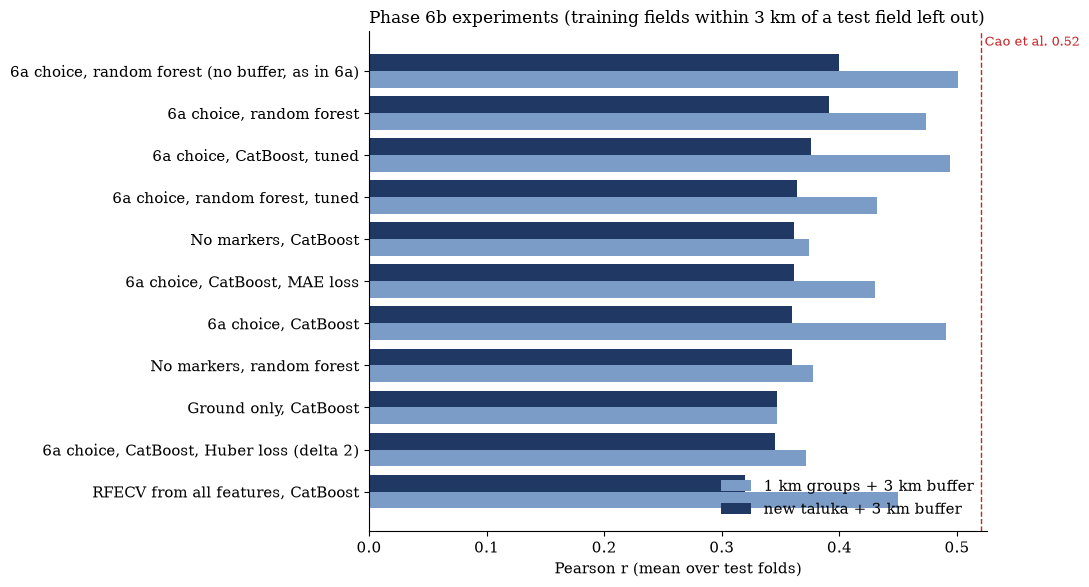

saved: ['P6b_experiments.csv', 'P6b_oof_predictions.csv', 'P6b_paired_tests.csv', 'P6b_rfecv_feature_frequency.csv', 'P6b_tuning_choices.csv']


In [9]:
# Step 8: figure, and save the out-of-fold predictions
order = EXP.sort_values("new taluka r")["experiment"]
fig, ax = plt.subplots(figsize=(11, 6)); yy = np.arange(len(order))
for off, col, lab, colr in [(-0.2, "group r", "1 km groups + 3 km buffer", "#7A9CC6"), (0.2, "new taluka r", "new taluka + 3 km buffer", "#1F3864")]:
    v = EXP.set_index("experiment").loc[order, col]; ax.barh(yy + off, v, 0.4, label=lab, color=colr)
ax.set_yticks(yy, order); ax.axvline(0.52, color="#C62828", ls="--", lw=1); ax.text(0.52, len(order) - 0.4, " Cao et al. 0.52", color="#C62828", fontsize=9)
ax.set_xlabel("Pearson r (mean over test folds)"); ax.legend(frameon=False, loc="lower right")
ax.set_title("Phase 6b experiments (training fields within 3 km of a test field left out)", loc="left", fontsize=12)
fig.tight_layout(); fig.savefig(FIG / "P6b_experiments.png", dpi=250, facecolor="white"); plt.show()
pd.concat([oof.assign(experiment=k) for k, (_, _, oof) in RES.items()]).to_csv(OUT / "P6b_oof_predictions.csv", index=False)
print("saved:", sorted(p.name for p in OUT.glob("P6b_*")))

## Summary

_(fill after running)_